# 02. Baseline

TF-IDF over words and bigrams + logistic regression with default settings, trained by `make train-baseline` on the stratified 80/20 split. This notebook reads the saved model and metrics and fixes the baseline as the reference point for the next days.

In [1]:
import joblib
import pandas as pd
from IPython.display import Image

from itg_classification.config import (
    FIGURES_DIR,
    MODELS_DIR,
    RESULTS_DIR,
    TEST_PATH,
)
from itg_classification.features import top_features
from itg_classification.metrics import (
    comparison_table,
    load_metrics,
    per_class_table,
)
from itg_classification.preprocess import decode_labels, preprocess_text
from itg_classification.split import load_split
from itg_classification.train_baseline import BASELINE_NAME

pd.set_option("display.max_colwidth", 150)

## 1. Scores on the test set

In [2]:
results = load_metrics(RESULTS_DIR / "baseline_metrics.json")
results["train_rows"], results["test_rows"]

(3842, 961)

In [3]:
comparison_table(results["models"], reference=BASELINE_NAME).round(3)

,macro_f1,accuracy,weighted_f1,negative_recall,macro_f1_change
Majority class,0.235,0.543,0.382,0.000,-0.651
Baseline TF-IDF + LogReg,0.672,0.795,0.783,0.261,0.000


In [4]:
per_class_table(results["models"][BASELINE_NAME]).round(3)

,precision,recall,f1,support
negative,0.947,0.261,0.409,69
neutral,0.799,0.908,0.850,522
positive,0.779,0.735,0.757,370


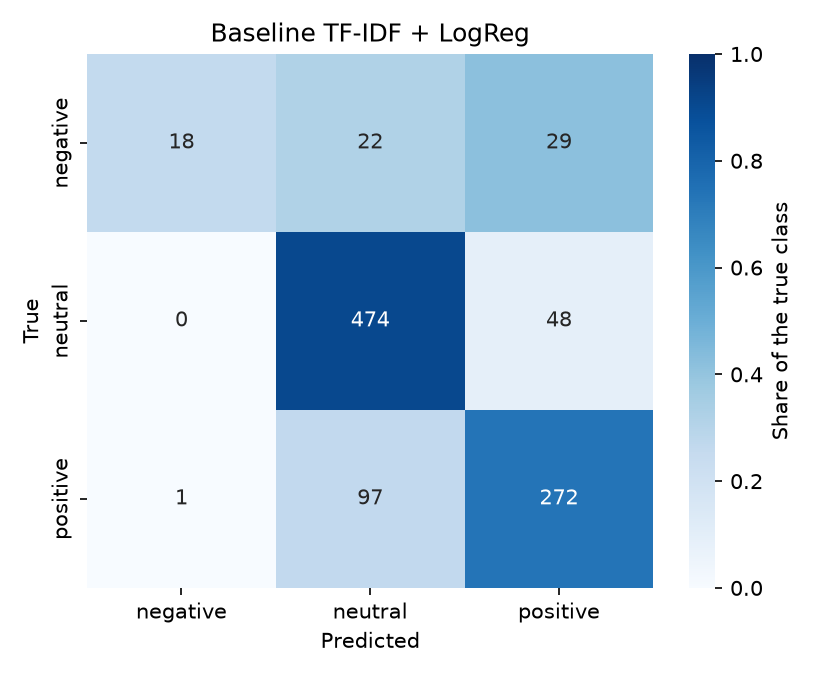

In [5]:
Image(FIGURES_DIR / "confusion_matrix_baseline.png")

- The baseline is far above the majority class: macro F1 0.672 against 0.235.
- `negative` is the weak class: precision 0.95, but recall only 0.26. The model predicts it only when it is very sure, a typical effect of the 7.6 : 1 imbalance without class weights.
- `negative` texts go to `positive` (29) more often than to `neutral` (22).
- Accuracy 0.795 hides the problem, macro F1 shows it.

## 2. What the model has learned

In [6]:
model = joblib.load(MODELS_DIR / "baseline.joblib")
top_features(model, n=15)

,negative,neutral,positive
0,down,the,long
1,short,is,up
2,spy,and,increase
3,tsla,of,year
4,lower,will,increased
5,fall,be,positive
6,price,approximately,buy
7,weak,not,higher
8,tesco,includes,strong
9,aapl,will be,to


- `positive` and `negative` rely partly on sentiment words: `up`, `increase`, `strong`, `growth` against `down`, `lower`, `fall`, `weak`.
- But `negative` also relies on tickers and company names: `tsla`, `spy`, `aapl`, `sbux`, `tesco`, `shell`, `deutsche`. The model memorizes which companies had bad news in train.
- `neutral` relies on function words: `the`, `is`, `and`, `of`, `will be`. They mark the style of long news sentences, which are mostly neutral, not the sentiment.

## 3. Tweets against news

Texts with a cashtag are the tweets and short headlines.

In [7]:
test = load_split(TEST_PATH)
test["predicted"] = model.predict(test["text"])
test["correct"] = test["predicted"] == test["label_id"]
test["source"] = (
    test["raw_text"]
    .str.contains(r"\$[A-Za-z]")
    .map({True: "with cashtag", False: "without cashtag"})
)
test.groupby("source").agg(
    texts=("correct", "size"), accuracy=("correct", "mean")
).round(3)

,texts,accuracy
source,,
with cashtag,151,0.629
without cashtag,810,0.826


In [8]:
pd.crosstab(
    [test["source"], test["label"]],
    pd.Series(decode_labels(test["predicted"]), name="predicted"),
)

predicted                 negative  neutral  positive
source          label                                
with cashtag    negative        14       16        20
                neutral          0        1         6
                positive         1       13        80
without cashtag negative         4        6         9
                neutral          0      473        42
                positive         0       84       192

- 50 of the 69 `negative` test texts are tweets, so the weak class is mostly a tweet class.
- On tweets the model is right in 63% of cases, on news sentences in 83%.
- Missed `negative` tweets split between `positive` (20) and `neutral` (16): tweets about falling prices often share words like `price`, `support` or a ticker with positive tweets.

## 4. New texts

In [9]:
new_texts = [
    "Profit fell sharply in the third quarter",
    "The company reported a net loss of EUR 5 million",
    "Sales rose 20% year-on-year",
    "The annual general meeting will be held in Helsinki",
]
processed = [preprocess_text(text) for text in new_texts]
probabilities = model.predict_proba(processed)
pd.DataFrame(
    probabilities.round(2),
    index=new_texts,
    columns=decode_labels(model.classes_),
).assign(predicted=decode_labels(probabilities.argmax(axis=1)))

,negative,neutral,positive,predicted
Profit fell sharply in the third quarter,0.03,0.36,0.61,positive
The company reported a net loss of EUR 5 million,0.02,0.62,0.35,neutral
Sales rose 20% year-on-year,0.03,0.03,0.94,positive
The annual general meeting will be held in Helsinki,0.01,0.94,0.04,neutral


- *Profit fell sharply in the third quarter* comes out as `positive` (0.61): `profit` and `quarter` are frequent in positive news, and they outweigh `fell`.
- *Net loss of EUR 5 million* comes out as `neutral`.
- The probability of `negative` stays at 0.02-0.03 even for clearly negative sentences.

## 5. Reference point

| Model | Macro F1 | Accuracy | Negative recall |
|---|---|---|---|
| Majority class | 0.235 | 0.543 | 0.000 |
| **Baseline TF-IDF + LogReg** | **0.672** | 0.795 | 0.261 |

Every improvement is compared with the baseline macro F1 **0.672** on the same test set. The goal is at least +5%, macro F1 0.706 or higher.

What to try first, from the findings above:

1. Class weights, to raise the `negative` recall.
2. A tokenizer that keeps negations like `can't`.
3. Other models and tuned regularization.

The reliance on tickers and company names is a question for the error analysis.